<a href="https://colab.research.google.com/github/keyvanmahmoudi/Machine_Learning_Course/blob/main/solutions/Session01_ml_workflow_solutions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

# پاسخ تمرین‌های جلسهٔ ۱: مقدمه‌ای بر یادگیری ماشین و جریان کار آن

این نوت‌بوک پاسخ پیشنهادی تمرین‌های انتهای [نوت‌بوک جلسه](../sessions/Session01_ml_workflow.ipynb) است. قبل از دیدن پاسخ‌ها، خودتان تمرین‌ها را حل کنید؛ معمولاً بیش از یک راه‌حل درست وجود دارد.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### آماده‌سازی

کتابخانه‌ها و داده‌هایی که پاسخ‌ها به آن‌ها نیاز دارند:

</div>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, load_wine
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
import seaborn as sns

sns.set_theme(style="whitegrid")

iris = load_iris(as_frame=True)
X, y = iris.data, iris.target

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۱

داده را با `test_size=0.2` و `random_state` متفاوت تقسیم کنید. دقت مدل چقدر تغییر می‌کند؟ چه نتیجه‌ای می‌گیرید؟

</div>

In [2]:
scores = []
for seed in range(10):
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=seed)
    scores.append(KNeighborsClassifier(n_neighbors=5).fit(X_tr, y_tr).score(X_te, y_te))

print("Accuracy for 10 different splits:", np.round(scores, 3))
print(f"min = {min(scores):.3f}, max = {max(scores):.3f}, mean = {np.mean(scores):.3f}")

Accuracy for 10 different splits: [1.    0.967 0.967 0.933 0.933 0.967 0.933 1.    0.967 1.   ]
min = 0.933, max = 1.000, mean = 0.967


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

با دادهٔ آزمون کوچک (۳۰ گل)، هر اشتباه حدود ۳ درصد دقت را تغییر می‌دهد و نتیجه بسته به اینکه کدام گل‌ها در آزمون باشند، بالا و پایین می‌رود. **نتیجه:** یک بار تقسیم، تخمین نویزداری از عملکرد می‌دهد. در جلسهٔ ۱۰ با **اعتبارسنجی متقابل** این مشکل را حل می‌کنیم.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۲

فقط از دو ویژگی گلبرگ (`petal length` و `petal width`) استفاده کنید. دقت بهتر شد یا بدتر؟ چرا؟

</div>

In [3]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)
petal = ["petal length (cm)", "petal width (cm)"]

all_features = KNeighborsClassifier(n_neighbors=5).fit(X_tr, y_tr).score(X_te, y_te)
petal_only = KNeighborsClassifier(n_neighbors=5).fit(X_tr[petal], y_tr).score(X_te[petal], y_te)
print(f"All 4 features: {all_features:.3f}")
print(f"Petal features: {petal_only:.3f}")

All 4 features: 0.978
Petal features: 0.933


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

با دو ویژگی گلبرگ، دقت روی این تقسیم کمی پایین‌تر است؛ تفاوت فقط **دو گل** از ۴۵ گل آزمون است. در تمرین ۱ دیدیم که دقت با عوض شدن تقسیم به همین اندازه بالا و پایین می‌رود، پس از یک تقسیم نمی‌توان نتیجه گرفت کدام بهتر است. نکتهٔ مهم‌تر: فقط با ۲ ویژگی از ۴ ویژگی، بیش از ۹۰٪ دقت حفظ شده است؛ همان‌طور که در نمودار اکتشافی دیدیم، بیشتر اطلاعات در ویژگی‌های گلبرگ است. اگر دو مدل دقت یکسانی داشته باشند، مدل ساده‌تر با ویژگی‌های کمتر بهتر است.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۳

به‌جای k-NN از `DecisionTreeClassifier` (از `sklearn.tree`) استفاده کنید. تنها تغییر لازم در کد کدام خط است؟

</div>

In [4]:
tree = DecisionTreeClassifier(random_state=42)     # the only line that changes
tree.fit(X_tr, y_tr)
print(f"Decision tree accuracy: {tree.score(X_te, y_te):.3f}")

Decision tree accuracy: 0.933


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

فقط خط ساختن مدل عوض می‌شود. `fit`، `predict` و `score` دقیقاً همان‌اند. این قدرت رابط یکسان scikit-learn است: امتحان کردن مدل‌های مختلف فقط یک خط کد هزینه دارد.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۴

مجموعه‌دادهٔ `load_wine` را بارگذاری کنید و همین جریان کار را از ابتدا تا انتها روی آن اجرا کنید.

</div>

(178, 13)
{0: 59, 1: 71, 2: 48}
Baseline accuracy: 0.389
k-NN accuracy:     0.722


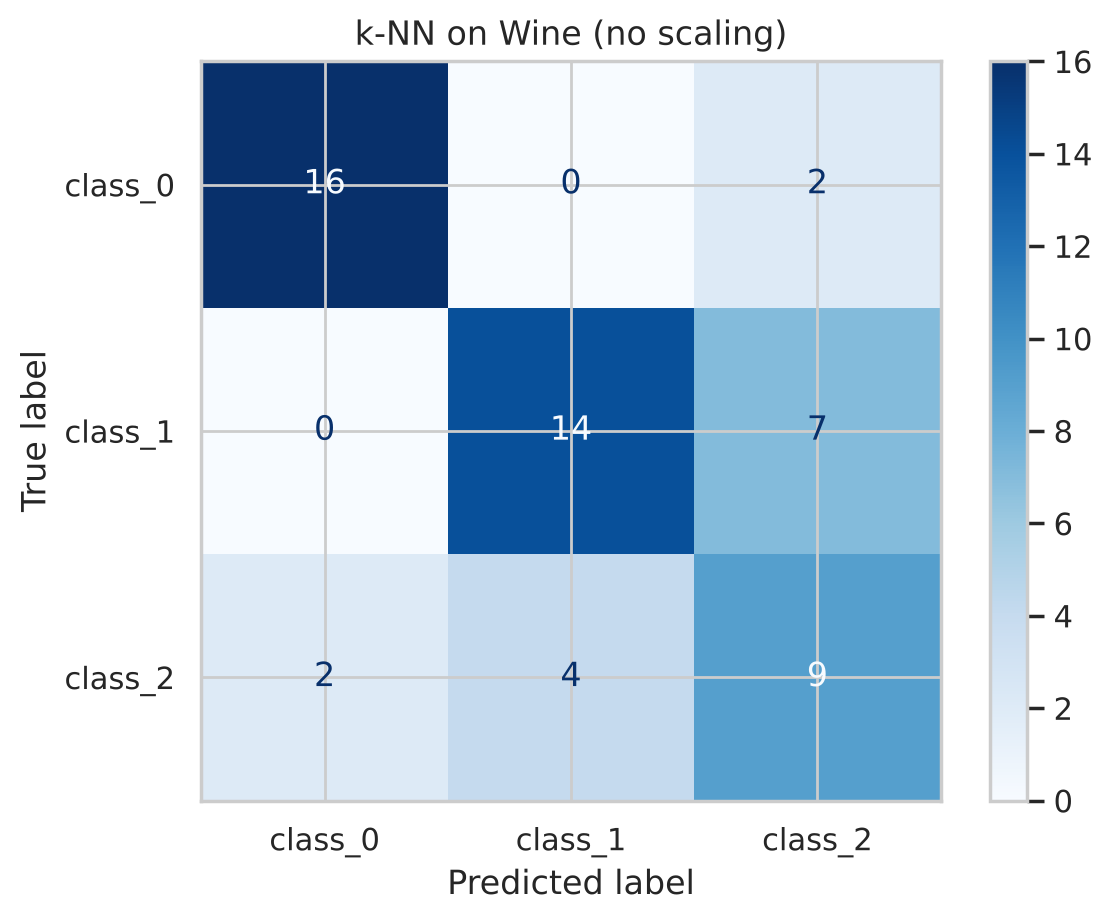

In [5]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import ConfusionMatrixDisplay

wine = load_wine(as_frame=True)
print(wine.data.shape)
print(wine.target.value_counts().sort_index().to_dict())

Xw_tr, Xw_te, yw_tr, yw_te = train_test_split(wine.data, wine.target, test_size=0.3,
                                              stratify=wine.target, random_state=42)
baseline = DummyClassifier(strategy="most_frequent").fit(Xw_tr, yw_tr)
knn = KNeighborsClassifier(n_neighbors=5).fit(Xw_tr, yw_tr)
print(f"Baseline accuracy: {baseline.score(Xw_te, yw_te):.3f}")
print(f"k-NN accuracy:     {knn.score(Xw_te, yw_te):.3f}")

ConfusionMatrixDisplay.from_estimator(knn, Xw_te, yw_te, display_labels=wine.target_names, cmap="Blues")
plt.title("k-NN on Wine (no scaling)")
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

داده ۱۷۸ نمونه، ۱۳ ویژگی و سه کلاس دارد. k-NN از مدل پایه بهتر است، ولی دقتش نسبت به Iris پایین‌تر است. دلیل اصلی را در جلسهٔ ۶ می‌بینیم: ویژگی‌های Wine مقیاس‌های بسیار متفاوتی دارند (مثلاً `proline` تا حدود ۱۷۰۰) و k-NN بدون **مقیاس‌بندی** عملاً فقط به ویژگی‌های بزرگ نگاه می‌کند. با افزودن `StandardScaler` (جلسهٔ ۲) دقت به‌طور چشمگیری بالا می‌رود.

</div>